# W-state QSS — numerical experiments

Run the cells in order. The notebook constructs the protocol circuits, executes fresh Aer measurements and evaluates the experiments in Section 4. IBM execution uses your saved IBM Quantum account and the processor specified by `IBM_BACKEND` (default: `ibm_kingston`). Measurement datasets from `ibm_fez` and `ibm_marrakesh` are also provided in `qss_measurements`. To analyze another processor's measurements, change `IBM_BACKEND` before running the notebook. No credentials belong in this notebook.

Required packages: `qiskit`, `qiskit-aer`, `qiskit-ibm-runtime`, `numpy`, `scipy`, `matplotlib` and `pylatexenc`. Install them in the notebook's Python environment if needed:

```python
%pip install qiskit qiskit-aer qiskit-ibm-runtime numpy scipy matplotlib pylatexenc
```

Hardware counts are loaded from `qss_measurements/<experiment>_<backend>.json`. The notebook loads the required IBM measurement files when they are available and checks that their contents are valid and complete. If a file is missing, the corresponding experiment is run automatically on IBM Quantum hardware and the results are saved. An invalid or incomplete file raises an error. The supplied `ibm_kingston` files therefore allow the hardware comparisons to be reproduced without submitting new jobs. To obtain fresh hardware measurements, remove the corresponding file and rerun the acquisition cell.

The simulator and illustrative run are recomputed. No random seeds are fixed. Statistical reproduction means agreement within sampling uncertainty, rather than identical outcomes on a changing processor. The calibration/holdout split is fresh in each full run, so threshold projections may change.

Figures are saved as vector PDFs in `qss_figures`. On all measurement plots, Aer uses large open circles and IBM uses smaller filled squares, making overlapping estimates visible without moving their coordinates. The threshold axes use $m_T$, the number of test rounds; $m$ remains the total protocol-round count.

The cumulative plots test the formulas of Section 3: detection before collecting a secret of length $n$. Information rounds and retained semi-information rounds are each used to transmit one secret bit. Each protocol run continues until its first forbidden outcome or collection of the largest requested secret length, with no fixed limit on the number of attempted rounds. Each point is an empirical abort frequency for that secret prefix from fresh Aer shots. The hardware threshold experiment separately uses $m_T$ test rounds.


## 0. Protocol implementation

In [3]:
import json
import random
from collections import Counter
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
from scipy.optimize import brentq
from scipy.stats import binom
from scipy.special import xlogy
from qiskit import ClassicalRegister, QuantumCircuit, QuantumRegister
from qiskit_aer import AerSimulator

IBM_BACKEND = "ibm_kingston"
EM_CONTROL_SHOTS = 256
QPU_SHOTS = {"efficiency": 1024, "ir": 256, "em": 512, "information": 2048}
AER_SHOTS = 2048
ANCILLA_AER_SHOTS = 8192
CUMULATIVE_RUNS = 1000
CONFIDENCE_LEVEL = 0.95

DATA_DIR = Path("qss_measurements")
FIGURE_DIR = Path("qss_figures")
DATA_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(exist_ok=True)

THETA = np.array([0, np.pi / 4, np.pi / 3, np.pi / 2, 3 * np.pi / 4, np.pi])
THETA_NONZERO = THETA[1:]
THETA_NAMES = [r"$\pi/4$", r"$\pi/3$", r"$\pi/2$", r"$3\pi/4$", r"$\pi$"]
SECRET_LENGTHS = np.array([10, 20, 40, 80])
CUMULATIVE_LENGTHS = np.array([0, 10, 20, 40, 60, 80, 100])
TEST_COUNTS = np.arange(10, 201, 10)
ALPHAS = (0.01, 0.05)
CALIBRATION_DELTA = 0.05

THEORY = "0.3"
AER = "#d97706"
IBM = "#0f766e"
CONTROL = "#b4535a"
THETA_COLORS = plt.rcParams["axes.prop_cycle"].by_key()["color"][:5]
plt.rcParams.update({"figure.figsize": (8, 5), "font.size": 10,
                     "axes.grid": True, "grid.alpha": 0.22,
                     "axes.spines.top": True, "axes.spines.right": True,
                     "axes.axisbelow": True})

simulator = AerSimulator()  # Deliberately unseeded: each run samples new outcomes.


def finish_plot(fig, filename):
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / filename, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def pad_probability_axes(ax, xmax=None, ymax=1):
    if xmax is not None:
        ax.set_xlim(-0.045 * xmax, 1.045 * xmax)
    ax.set_ylim(-0.045 * ymax, 1.07 * ymax)


def interval_errors(point, ci):
    point, ci = np.asarray(point), np.asarray(ci)
    errors = np.vstack((point - ci[0], ci[1] - point))
    if not np.all(np.isfinite(errors)) or np.any(errors < -1e-12):
        raise ValueError("Confidence bounds must contain the plotted estimate")
    return np.maximum(0, errors)

# The open Aer circle remains visible around the smaller IBM square.
SERIES_STYLE = {
    "Aer": dict(fmt="o", color=AER, markersize=8.5,
                markerfacecolor="none", markeredgewidth=1.5, zorder=4),
    "IBM": dict(fmt="s", color=IBM, markersize=4.8,
                markerfacecolor=IBM, markeredgewidth=1.0, zorder=3),
}


def plot_estimates(ax, x, y, ci, series, *, x_ci=None, label=None, color=None):
    """Use the same markers and confidence-bound style on every measurement plot."""
    source = "Qiskit Aer" if series == "Aer" else "IBM Quantum"
    style = SERIES_STYLE[series].copy()
    if color is not None:
        style["color"] = color
        if style["markerfacecolor"] != "none":
            style["markerfacecolor"] = color
    return ax.errorbar(
        x, y, yerr=interval_errors(y, ci),
        xerr=None if x_ci is None else interval_errors(x, x_ci),
        capsize=3, elinewidth=1.1, alpha=0.9,
        label=source + " (95% CI)" if label is None else label, **style,
    )

In [7]:
QUBITS = 3
X_PATTERNS = {0: [(0,), (0, 1, 2)], 1: [(), (1, 2)]}

impossible_outcomes_h1 = {
    (): {"101", "111"},
    (0,): {"100", "110"},
    (1, 2): {"001", "011"},
    (0, 1, 2): {"000", "010"},
}
impossible_outcomes_h2 = {
    (): {"011", "111"},
    (0,): {"010", "110"},
    (1, 2): {"001", "101"},
    (0, 1, 2): {"000", "100"},
}

In [11]:
def generate_w_state():
    state = QuantumCircuit(QUBITS, QUBITS)
    state.x(0)
    state.cry(2 * np.arccos(1 / np.sqrt(3)), 0, 1)
    state.cx(1, 0)
    state.cry(np.pi / 2, 1, 2)
    state.cx(2, 1)
    return state


def secret_bit_encode(state, secret_bit, x_pattern=None):
    """Apply the existing X-encoding rule; return the selected X pattern."""
    if secret_bit not in (0, 1):
        raise ValueError("Secret bit must be 0 or 1")
    x_pattern = tuple(random.choice(X_PATTERNS[secret_bit])
                      if x_pattern is None else x_pattern)
    if x_pattern not in X_PATTERNS[secret_bit]:
        raise ValueError("X pattern is incompatible with the secret bit")
    for qubit in x_pattern:
        state.x(qubit)
    return x_pattern


def hadamard_applying(state, alice_h=None):
    """Return Alice's H flags on Bob's and Charlie's qubits."""
    if alice_h is None:
        alice_h = (random.randrange(2), random.randrange(2))
    h1, h2 = map(int, alice_h)
    if h1:
        state.h(1)
    if h2:
        state.h(2)
    return h1, h2


def intercept_resend(state, qubit=2, attack_basis=None):
    """I&R on Charlie's qubit: the interceptor measures in a random X/Z basis."""
    if attack_basis is None:
        attack_basis = random.choice(("Z", "X"))
    if attack_basis not in ("Z", "X"):
        raise ValueError("Interception basis must be X or Z")
    eve_reg = ClassicalRegister(1, "intercept")
    state.add_register(eve_reg)
    if attack_basis == "X":
        state.h(qubit)
    state.measure(qubit, eve_reg[0])
    if attack_basis == "X":
        state.h(qubit)
    return attack_basis


def entangle_measure(state, theta, qubit=2):
    """E&M interaction with an ancilla, without measuring it."""
    ancilla = QuantumRegister(1, "anc")
    state.add_register(ancilla)
    state.cry(2 * theta, qubit, ancilla[0])


def basis_choice(state, alice_h, bases=None):
    """Return participant bases and effective H flags (h1, h2)."""
    if bases is None:
        bases = (random.choice(("Z", "X")),
                 random.choice(("Z", "X")))
    bob_basis, charlie_basis = bases
    if bob_basis not in ("Z", "X") or charlie_basis not in ("Z", "X"):
        raise ValueError("Measurement bases must be X or Z")
    if bob_basis == "X":
        state.h(1)
    if charlie_basis == "X":
        state.h(2)
    h1 = alice_h[0] ^ (bob_basis == "X")
    h2 = alice_h[1] ^ (charlie_basis == "X")
    return tuple(bases), (int(h1), int(h2))

In [9]:
def build_round(secret_bit, attack=None, theta=None, *,
                x_pattern=None, alice_h=None, bases=None, attack_basis=None):
    """Return a protocol circuit and its classical choices."""
    state = generate_w_state()
    x = secret_bit_encode(state, secret_bit, x_pattern)
    alice_h = hadamard_applying(state, alice_h)
    chosen_attack_basis = None

    if attack == "IR":
        chosen_attack_basis = intercept_resend(state, 2, attack_basis)
    elif attack == "EM":
        if theta is None:
            raise ValueError("theta is required for E&M")
        entangle_measure(state, theta)
    elif attack is not None:
        raise ValueError("Attack must be None, 'IR' or 'EM'")

    bases, (h1, h2) = basis_choice(state, alice_h, bases)
    state.measure(0, 0)
    state.measure(1, 1)
    state.measure(2, 2)

    metadata = {
        "secret_bit": secret_bit,
        "x_qubits": x,
        "alice_h": alice_h,
        "bases": bases,
        "h1": h1,
        "h2": h2,
        "attack": attack,
        "theta": theta,
        "attack_basis": chosen_attack_basis,
    }
    return state, metadata


def forbidden_outcomes(metadata):
    h1, h2 = metadata["h1"], metadata["h2"]
    if h1 == h2:
        return set()
    table = impossible_outcomes_h1 if h1 else impossible_outcomes_h2
    return table[metadata["x_qubits"]]


def classify_round(metadata, outcome):
    """Classify a measured round and flag forbidden outcomes."""
    h1, h2 = metadata["h1"], metadata["h2"]
    if h1 != h2:
        return "T", outcome in forbidden_outcomes(metadata)
    if h1 == 0:
        return "I", False
    accepted = (int(outcome[2]) == int(0 in metadata["x_qubits"])
                and random.random() < 0.5)
    return ("S-I" if accepted else "S-I*"), False


def recovered_bit(outcome, round_type):
    """Recover one bit from an accepted round."""
    return (outcome.count("1") % 2) ^ (round_type == "S-I")

In [506]:
def measure_aer(circuit):
    result = simulator.run(circuit, shots=1, memory=True).result()
    return result.get_memory(0)[0].split()[-1]


def execute_protocol(secret):
    """Perform complete rounds until the secret is reconstructed or a test fails."""
    bits = tuple(secret)
    if not bits or any(bit not in (0, 1, "0", "1") for bit in bits):
        raise ValueError("Expected a nonempty binary secret")
    bits = tuple(map(int, bits))
    recovered, log = [], []
    for bit in bits:
        while True:
            circuit, metadata = build_round(bit)
            outcome = measure_aer(circuit)
            kind, forbidden = classify_round(metadata, outcome)
            log.append((metadata, outcome, kind, forbidden))
            if forbidden:
                return None, log
            if kind in ("I", "S-I"):
                recovered.append(int(recovered_bit(outcome, kind)))
                break
    return recovered, log


def display_protocol_run(secret="01001", columns=8):
    """Print dynamically generated gate choices, measurements and recovered bits."""
    if not isinstance(columns, int) or columns < 1:
        raise ValueError("Column count must be a positive integer")
    bits = tuple(secret)
    recovered, log = execute_protocol(bits)
    rows = {name: [] for name in ("X", "H", "Basis", "Round", "Outcome")}

    def gates(name, positions):
        return ", ".join(f"{name}{q}" for q in positions) or "I"

    for meta, outcome, round_type, forbidden in log:
        positions = [q for q, used in zip((1, 2), meta["alice_h"]) if used]
        rows["X"].append(gates("X", meta["x_qubits"]))
        rows["H"].append(gates("H", positions))
        rows["Basis"].append(", ".join(meta["bases"]))
        rows["Round"].append(round_type + ("!" if forbidden else ""))
        rows["Outcome"].append(outcome)

    for start in range(0, len(log), columns):
        stop = min(start + columns, len(log))
        widths = [max(len(rows[k][j]) for k in rows) for j in range(start, stop)]
        for name, values in rows.items():
            entries = " | ".join(f"{val:<{width}}" for val, width in
                                 zip(values[start:stop], widths))
            print(f"{name + ':':<12}{entries}")
        if stop < len(log):
            print()
    print("Recovered: ", " ".join(map(str, recovered)) if recovered is not None
          else "Not released (test failed)")
    print("Secret:    ", " ".join(str(int(bit)) for bit in bits))
    return recovered, log


recovered_example, round_log = display_protocol_run("01001")

X:          X0, X1, X2 | X1, X2 | X1, X2 | X0   | X0   | X0, X1, X2 | X0, X1, X2 | X0, X1, X2
H:          I          | H1, H2 | H1, H2 | I    | H1   | I          | I          | H2        
Basis:      Z, Z       | X, Z   | X, X   | Z, X | Z, Z | X, Z       | X, Z       | X, X      
Round:      I          | T      | I      | T    | T    | T          | T          | T         
Outcome:    101        | 111    | 111    | 111  | 010  | 001        | 011        | 011       

X:          X0   | X0   | X0, X1, X2 | X0, X1, X2 | X0, X1, X2 | X0   | X0   | X0  
H:          H1   | H2   | I          | H1, H2     | H1         | I    | H2   | I   
Basis:      Z, Z | X, X | Z, Z       | Z, Z       | Z, X       | Z, X | X, Z | X, X
Round:      T    | T    | I          | S-I*       | S-I*       | T    | S-I* | S-I*
Outcome:    101  | 001  | 101        | 010        | 100        | 000  | 010  | 110 

X:          X0, X1, X2 | X1, X2
H:          I          | H1    
Basis:      X, X       | X, Z  
Round:      

In [507]:
# One representative test circuit; this fixes the illustration, not a random seed.
example_circuit, _ = build_round(
    1, x_pattern=(), alice_h=(0, 1), bases=("Z", "Z")
)
fig = example_circuit.draw("mpl")
finish_plot(fig, "00_example_round.pdf")

In [13]:
def binary_entropy(p):
    p = np.asarray(p, dtype=float)
    if np.any(~np.isfinite(p) | (p < 0) | (p > 1)):
        raise ValueError("Entropy requires probabilities between 0 and 1")
    return -(xlogy(p, p) + xlogy(1 - p, 1 - p)) / np.log(2)


def p_detection(attack, theta=None):
    if attack == "IR":
        return 1 / 48
    if attack == "EM" and theta is not None:
        return (1 - np.cos(theta)) / 48
    raise ValueError("Expected IR, or EM with theta")


def information_theory(theta):
    return 1 - binary_entropy((1 - np.abs(np.sin(theta))) / 2)


def ancilla_measurement_circuit(theta, input_bit):
    circuit = QuantumCircuit(1, 1)
    if input_bit:
        circuit.x(0)
    entangle_measure(circuit, theta, qubit=0)
    circuit.ry(np.pi / 2 - theta, circuit.qubits[-1])
    circuit.measure(circuit.qubits[-1], 0)
    return circuit


def information_from_counts(counts_0, counts_1):
    """Mutual information for two equiprobable inputs and a binary output."""
    n0, n1 = sum(counts_0.values()), sum(counts_1.values())
    if min(n0, n1) <= 0:
        raise ValueError("Both input states require nonempty measurements")
    p0, p1 = counts_0.get("1", 0) / n0, counts_1.get("1", 0) / n1
    value = binary_entropy((p0 + p1) / 2) - (
        binary_entropy(p0) + binary_entropy(p1)) / 2
    return float(np.clip(value, 0, 1))

### Measurements

In [14]:
def configuration_keys(attack=None):
    """Enumerate all physical choices, including both encoded bit values."""
    if attack not in (None, "IR", "EM"):
        raise ValueError("Attack must be None, 'IR' or 'EM'")
    for bit in (0, 1):
        for x in X_PATTERNS[bit]:
            for alice_h in product((0, 1), repeat=2):
                for bases in product(("Z", "X"), repeat=2):
                    key = (bit, x, *alice_h, *bases)
                    if attack == "IR":
                        for intercept_basis in ("Z", "X"):
                            yield key + (intercept_basis,)
                    else:
                        yield key


def prepare_templates(attack=None, theta=None):
    """Construct each physical configuration once, without collapsing H pairs."""
    templates = {}
    for key in configuration_keys(attack):
        bit, x, a1, a2, b1, b2 = key[:6]
        templates[key] = build_round(
            bit, attack, theta, x_pattern=x,
            alice_h=(a1, a2), bases=(b1, b2),
            attack_basis=key[6] if attack == "IR" else None,
        )[0]
    return templates


def aer_measure_templates(templates, shots):
    """One batched simulator call per family; no per-round simulator jobs."""
    keys, circuits = list(templates), list(templates.values())
    result = simulator.run(circuits, shots=shots).result()
    measurements = {}
    for i, key in enumerate(keys):
        # I&R adds the interception register; retain only Alice/Bob/Charlie bits.
        counts = Counter()
        for bits, frequency in result.get_counts(i).items():
            counts[bits.split()[-1]] += frequency
        measurements[key] = dict(counts)
    return measurements


def measure_information_aer(shots=ANCILLA_AER_SHOTS):
    circuits = [ancilla_measurement_circuit(theta, bit)
                for theta in THETA for bit in (0, 1)]
    results = simulator.run(circuits, shots=shots).result()
    return {float(theta): (dict(results.get_counts(2 * i)),
                           dict(results.get_counts(2 * i + 1)))
            for i, theta in enumerate(THETA)}


# All numerical data are obtained by executing the quantum circuits below.
aer_clean_raw = aer_measure_templates(prepare_templates(), AER_SHOTS)
aer_ir_raw = aer_measure_templates(prepare_templates("IR"), AER_SHOTS)
aer_em_raw = {float(t): aer_measure_templates(prepare_templates("EM", t), AER_SHOTS)
              for t in THETA}
aer_information_raw = measure_information_aer()

### IBM Quantum measurements


In [ ]:
# Reuse cached hardware measurements and acquire only missing datasets.

def dataset_path(kind):
    return DATA_DIR / f"{kind}_{IBM_BACKEND}.json"


def serialize_templates(data):
    return [{"key": [list(v) if isinstance(v, tuple) else v for v in key],
             "counts": values} for key, values in data.items()]


def deserialize_templates(records):
    data = {tuple(tuple(v) if isinstance(v, list) else v for v in row["key"]):
            row["counts"] for row in records}
    if len(data) != len(records):
        raise ValueError("Duplicate configurations in hardware dataset")
    return data


def save_dataset(kind, obj):
    validate_dataset(kind, obj)
    if kind == "information":
        payload = {"backend": IBM_BACKEND, "data": [
            {"theta": theta, "counts": list(count_pair)}
            for theta, count_pair in obj.items()]}
    elif kind == "efficiency":
        payload = {"backend": IBM_BACKEND, "data": serialize_templates(obj)}
    elif kind == "ir":
        payload = {"backend": IBM_BACKEND,
                   "clean": serialize_templates(obj["clean"]),
                   "IR": serialize_templates(obj["IR"])}
    else:
        payload = {"backend": IBM_BACKEND, "clean": serialize_templates(obj["clean"]),
                   "EM": [{"theta": theta, "data": serialize_templates(data)}
                          for theta, data in obj["EM"].items()]}
    payload["settings"] = {"theta_values": THETA.tolist() if kind in ("em", "information") else None}
    path = dataset_path(kind)
    temporary = path.with_suffix(".json.tmp")
    temporary.write_text(json.dumps(payload), encoding="utf-8")
    temporary.replace(path)


def load_dataset(kind):
    payload = json.loads(dataset_path(kind).read_text(encoding="utf-8"))
    if payload["backend"] != IBM_BACKEND:
        raise ValueError("Dataset backend mismatch")
    if kind == "information":
        obj = {float(x["theta"]): tuple(x["counts"]) for x in payload["data"]}
    elif kind == "efficiency":
        obj = deserialize_templates(payload["data"])
    elif kind == "ir":
        obj = {k: deserialize_templates(payload[k]) for k in ("clean", "IR")}
    else:
        obj = {"clean": deserialize_templates(payload["clean"]),
               "EM": {float(x["theta"]): deserialize_templates(x["data"])
                      for x in payload["EM"]}}
    validate_dataset(kind, obj)
    return obj


def validate_dataset(kind, obj):
    """Require complete configurations, the intended angles and integer shot counts."""
    if kind not in QPU_SHOTS:
        raise ValueError(f"Unknown experiment: {kind}")
    if kind in ("em", "information"):
        grid = obj["EM"] if kind == "em" else obj
        if len(grid) != len(THETA) or not np.allclose(
                sorted(grid), THETA, rtol=0, atol=1e-12):
            raise ValueError(f"Incomplete theta grid in IBM {kind} dataset")
    if kind == "information":
        if any(len(pair) != 2 for pair in obj.values()):
            raise ValueError("Ancilla data require measurements for both input states")
        families = [(pair, None, 1) for pair in obj.values()]
    elif kind == "efficiency":
        families = [(obj.values(), (obj, None), 3)]
    else:
        families = [(obj["clean"].values(), (obj["clean"], None), 3)]
        attacks = {"IR": obj["IR"]} if kind == "ir" else obj["EM"]
        for data in attacks.values():
            families.append((data.values(), (data, "IR" if kind == "ir" else "EM"), 3))
    for rows, configuration, width in families:
        if configuration is not None:
            data, attack = configuration
            if set(data) != set(configuration_keys(attack)):
                raise ValueError(f"Incomplete configurations in IBM {kind} dataset")
        sizes = set()
        for counts in rows:
            if not isinstance(counts, dict) or not counts or any(
                    not isinstance(s, str) or len(s) != width or set(s) - {"0", "1"}
                    or type(v) is not int or v < 0 for s, v in counts.items()):
                raise ValueError(f"Invalid measurement counts in IBM {kind} dataset")
            sizes.add(sum(counts.values()))
        if len(sizes) != 1 or min(sizes) <= 0:
            raise ValueError(f"Unequal or empty shot sets in IBM {kind} dataset")


def ibm_measure_circuits(circuits, shots, runtime):
    backend, sampler, passmanager = runtime
    print(f"Transpiling {len(circuits)} circuits for {backend.name}...", flush=True)
    isa = passmanager.run(circuits)
    job = sampler.run(isa, shots=shots)
    print(f"IBM job {job.job_id()}: {len(circuits)} circuits, "
          f"{shots} shots per circuit; waiting for results...", flush=True)
    results = job.result()
    counts = [dict(result.data.c.get_counts()) for result in results]
    if len(counts) != len(circuits) or any(sum(c.values()) != shots for c in counts):
        raise ValueError(f"Incomplete IBM results for job {job.job_id()}")
    print(f"IBM job {job.job_id()} completed.", flush=True)
    return counts


def acquire_dataset(kind, runtime):
    shots = QPU_SHOTS[kind]
    if kind == "information":
        circuits = [ancilla_measurement_circuit(t, bit)
                    for t in THETA for bit in (0, 1)]
        counts = ibm_measure_circuits(circuits, shots, runtime)
        return {float(t): (counts[2 * i], counts[2 * i + 1])
                for i, t in enumerate(THETA)}

    if kind == "efficiency":
        templates = prepare_templates()
        counts = ibm_measure_circuits(list(templates.values()), shots, runtime)
        return dict(zip(templates, counts))

    clean = prepare_templates()
    if kind == "ir":
        attacked = prepare_templates("IR")
        cases = [("clean", clean), ("IR", attacked)]
    elif kind == "em":
        clean_counts = ibm_measure_circuits(
            list(clean.values()), EM_CONTROL_SHOTS, runtime
        )
        cases = [
            (float(theta), prepare_templates("EM", theta))
            for theta in THETA
        ]
    else:
        raise ValueError(kind)
    circuits = [c for _, templates in cases for c in templates.values()]
    counts = ibm_measure_circuits(circuits, shots, runtime)
    result, index = {}, 0
    for label, templates in cases:
        next_index = index + len(templates)
        result[label] = dict(zip(templates, counts[index:next_index]))
        index = next_index
    if kind == "em":
        return {"clean": dict(zip(clean, clean_counts)), "EM": result}
    return result


DATASET_KINDS = ("efficiency", "ir", "em", "information")
qpu = {}
for kind in DATASET_KINDS:
    if dataset_path(kind).exists():
        qpu[kind] = load_dataset(kind)
        print(f"Loaded IBM {kind}: {dataset_path(kind)}", flush=True)

missing = [kind for kind in DATASET_KINDS if kind not in qpu]
if missing:
    from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler
    from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
    service = QiskitRuntimeService()
    backend = service.backend(IBM_BACKEND)
    runtime = (backend, Sampler(mode=backend),
               generate_preset_pass_manager(backend=backend, optimization_level=1))
    print(f"Acquiring missing datasets on {backend.name}: {', '.join(missing)}",
          flush=True)
    for kind in missing:
        print(f"Starting IBM {kind} experiment...", flush=True)
        measured = acquire_dataset(kind, runtime)
        save_dataset(kind, measured)
        qpu[kind] = measured
        print(f"Saved IBM {kind}: {dataset_path(kind)}", flush=True)
print("All IBM datasets are available.", flush=True)

Loaded IBM efficiency: qss_measurements\efficiency_ibm_kingston.json
Loaded IBM ir: qss_measurements\ir_ibm_kingston.json
Loaded IBM em: qss_measurements\em_ibm_kingston.json
Loaded IBM information: qss_measurements\information_ibm_kingston.json
All IBM datasets are available.


### Statistical analysis

Error bars are conservative, pointwise 95% confidence bounds obtained by inverting KL/Chernoff bounds for independent Bernoulli outcomes. Each configuration is measured the same number of times, so pooling the results is equivalent to averaging the estimated probabilities. The event probabilities may differ between configurations. Zero observed events therefore retain a positive upper bound.

The acceptance bounds hold jointly for both secret-bit values and are propagated through the inverse-yield calculation. Information bounds cover both conditional binary outcome probabilities jointly and are propagated through the mutual-information function. They remain nondegenerate for perfectly distinguishable observed outcomes. These are confidence bounds on population quantities, not prediction intervals for a future run or simultaneous confidence bands for an entire curve. Independence of shots and the stated configuration sampling are assumptions.

Method: W. Hoeffding, *Probability Inequalities for Sums of Bounded Random Variables*, JASA **58**, 13–30 (1963), https://doi.org/10.1080/01621459.1963.10500830.


In [4]:
def effective_h(metadata):
    bit, x, a1, a2, b1, b2 = metadata[:6]
    return int(bit), tuple(x), int(a1 ^ (b1 == "X")), int(a2 ^ (b2 == "X"))


def bernoulli_kl(p, q):
    if q == 0:
        return 0.0 if p == 0 else np.inf
    if q == 1:
        return 0.0 if p == 1 else np.inf
    value = 0.0
    if p > 0:
        value += p * np.log(p / q)
    if p < 1:
        value += (1 - p) * np.log((1 - p) / (1 - q))
    return value


def upper_probability_bound(k, n, delta):
    """KL/Chernoff bound for the mean of independent Bernoulli trials."""
    if n <= 0 or not 0 <= k <= n or not 0 < delta < 1:
        raise ValueError("Expected n > 0, 0 <= k <= n and 0 < delta < 1")
    if k == n:
        return 1.0
    if k == 0:
        return float(-np.expm1(np.log(delta) / n))
    p = k / n
    target = -np.log(delta) / n
    return float(brentq(lambda q: bernoulli_kl(p, q) - target, p, 1.0,
                        xtol=1e-14))


def probability_interval(k, n, confidence=CONFIDENCE_LEVEL):
    """Conservative two-sided bounds, including zero and all-event samples."""
    if not 0 < confidence < 1:
        raise ValueError("Confidence level must lie between zero and one")
    tail = (1 - confidence) / 2
    return np.array([1 - upper_probability_bound(n - k, n, tail),
                     upper_probability_bound(k, n, tail)])


def aggregate_round_counts(data):
    """Pool raw events by encoded bit for yield, decoding and detection analyses."""
    attack = "IR" if data and len(next(iter(data))) == 7 else None
    if set(data) != set(configuration_keys(attack)):
        raise ValueError("Protocol configurations must be complete")
    totals = {bit: dict(info_shots=0, info_errors=0, valid_shots=0, valid=0,
                       semi_errors=0, test_shots=0, forbidden=0)
              for bit in (0, 1)}
    shot_sizes = set()
    for key, counts in data.items():
        bit, x, h1, h2 = effective_h(key)
        shots = sum(counts.values())
        shot_sizes.add(shots)
        row = totals[bit]
        if h1 != h2:
            forbidden = forbidden_outcomes({"x_qubits": x, "h1": h1, "h2": h2})
            row["test_shots"] += shots
            row["forbidden"] += sum(counts.get(s, 0) for s in forbidden)
        elif h1 == 0:
            row["info_shots"] += shots
            row["info_errors"] += sum(v for s, v in counts.items()
                                      if recovered_bit(s, "I") != bit)
        else:
            row["valid_shots"] += shots
            for s, v in counts.items():
                if int(s[2]) == int(0 in x):
                    row["valid"] += v
                    row["semi_errors"] += v * (recovered_bit(s, "S-I") != bit)
    if len(shot_sizes) != 1 or min(shot_sizes) <= 0:
        raise ValueError("Protocol intervals require equal positive shots per template")
    return totals


def round_statistics(data):
    """Protocol probabilities and pointwise confidence bounds."""
    totals = aggregate_round_counts(data)
    # Simultaneous bounds for both bit-conditioned acceptance probabilities.
    joint_confidence = 1 - (1 - CONFIDENCE_LEVEL) / 2
    accepted, detected, accept_ci, bit_errors = [], [], [], []
    for row in totals.values():
        p_valid = row["valid"] / row["valid_shots"]
        accepted.append(0.25 + 0.125 * p_valid)
        detected.append(0.5 * row["forbidden"] / row["test_shots"])
        wrong = (0.25 * row["info_errors"] / row["info_shots"]
                 + 0.125 * row["semi_errors"] / row["valid_shots"])
        bit_errors.append(wrong / accepted[-1])
        accept_ci.append(0.25 + 0.125 * probability_interval(
            row["valid"], row["valid_shots"], joint_confidence))
    # With equal shot counts, the pooled probability is the mean across test configurations.
    detection_bounds = 0.5 * probability_interval(
        sum(row["forbidden"] for row in totals.values()),
        sum(row["test_shots"] for row in totals.values()))
    return {"accept": np.asarray(accepted), "detect": np.asarray(detected),
            "accept_ci": np.column_stack(accept_ci), "detect_ci": detection_bounds,
            "bit_error_by_secret": np.asarray(bit_errors),
            "bit_error": float(np.mean(bit_errors))}


def single_detection(stats):
    return float(np.mean(stats["detect"]))


def expected_attempts(stats, n):
    return np.asarray(n) * np.mean(1 / stats["accept"])


def attempts_ci(stats, n):
    bounds = stats["accept_ci"]
    return np.array([np.mean(1 / bounds[1]), np.mean(1 / bounds[0])])[:, None] * np.asarray(n)


def information_stats(count_pair):
    """Map a joint confidence rectangle for the two binary channels into MI bounds."""
    info = information_from_counts(*count_pair)
    marginal_confidence = 1 - (1 - CONFIDENCE_LEVEL) / 2
    bounds = [probability_interval(counts.get("1", 0), sum(counts.values()),
                                  marginal_confidence) for counts in count_pair]
    def mutual_information(p0, p1):
        return information_from_counts({"0": 1 - p0, "1": p0},
                                       {"0": 1 - p1, "1": p1})
    # For fixed equiprobable inputs, MI is convex in the channel probabilities:
    # the maximum is attained at a corner; the minimum is zero if the ranges overlap.
    high = max(mutual_information(p0, p1) for p0, p1 in product(*bounds))
    if max(bounds[0][0], bounds[1][0]) <= min(bounds[0][1], bounds[1][1]):
        low = 0.0
    elif bounds[0][1] < bounds[1][0]:
        low = mutual_information(bounds[0][1], bounds[1][0])
    else:
        low = mutual_information(bounds[0][0], bounds[1][1])
    return {"information": info, "ci": np.array([max(0.0, low), min(1.0, high)])}

In [ ]:
def cumulative_detection(probability, lengths):
    """Section 3: detection before transmission of an n-bit secret is completed, with acceptance probability 1/3."""
    return 1 - np.power(1 / (1 + 3 * probability), np.asarray(lengths))


def aer_event_batch(templates, size, rng):
    """Fresh round events for uniformly sampled physical choices of one encoded bit."""
    keys = list(templates)
    choices = rng.integers(len(keys), size=size)
    allocations = np.bincount(choices, minlength=len(keys))
    result = simulator.run(list(templates.values()),
                           shots=int(allocations.max()), memory=True).result()
    forbidden = np.zeros(size, dtype=bool)
    selected = np.zeros(size, dtype=bool)
    for i, key in enumerate(keys):
        positions = np.flatnonzero(choices == i)
        if not positions.size:
            continue
        # Each candidate round receives a distinct freshly measured shot.
        memory = result.get_memory(i)[:positions.size]
        outcomes = np.fromiter((int(s.split()[-1], 2) for s in memory),
                               dtype=np.uint8, count=positions.size)
        _, x, h1, h2 = effective_h(key)
        if h1 != h2:
            impossible = forbidden_outcomes({"x_qubits": x, "h1": h1, "h2": h2})
            forbidden[positions] = np.isin(outcomes, [int(s, 2) for s in impossible])
        elif h1 == 0:
            selected[positions] = True
        else:
            selected[positions] = (((outcomes & 1) == int(0 in x))
                                   & (rng.random(positions.size) < 0.5))
    return forbidden, selected


def cumulative_aer(attack, theta=None, *, lengths=CUMULATIVE_LENGTHS,
                   runs=CUMULATIVE_RUNS):
    """Empirical abort probabilities before collection of each requested secret prefix."""
    lengths = np.asarray(lengths)
    if (lengths.ndim != 1 or lengths.size == 0
            or not np.issubdtype(lengths.dtype, np.integer)
            or np.any(lengths < 0) or np.any(np.diff(lengths) <= 0)):
        raise ValueError("Secret lengths must be strictly increasing nonnegative integers")
    if not isinstance(runs, (int, np.integer)) or runs <= 0:
        raise ValueError("Number of protocol runs must be a positive integer")
    templates = prepare_templates(attack, theta)
    per_bit = [{key: circuit for key, circuit in templates.items() if key[0] == bit}
               for bit in (0, 1)]
    maximum = int(lengths[-1])
    collected = np.zeros(runs, dtype=int)
    aborted = np.zeros(runs, dtype=bool)
    rounds_used = np.zeros(runs, dtype=int)
    if maximum:
        rng = np.random.default_rng()
        secrets = rng.integers(2, size=(runs, maximum))
        pools = [None, None]
        pointers = np.zeros(2, dtype=int)
        batch_size = runs * maximum
        active = np.arange(runs)
        while active.size:
            pending = secrets[active, collected[active]]
            rounds_used[active] += 1
            for bit in (0, 1):
                trajectories = active[pending == bit]
                if not trajectories.size:
                    continue
                start = pointers[bit]
                stop = start + trajectories.size
                if pools[bit] is None or stop > len(pools[bit][0]):
                    # Refill with new Aer shots; batch size is not a round cutoff.
                    pools[bit] = aer_event_batch(per_bit[bit], batch_size, rng)
                    start, stop = 0, trajectories.size
                forbidden, selected = pools[bit]
                failed = forbidden[start:stop]
                aborted[trajectories[failed]] = True
                advanced = selected[start:stop] & ~failed
                collected[trajectories[advanced]] += 1
                pointers[bit] = stop
            active = np.flatnonzero(~aborted & (collected < maximum))
        # No shot is reused; unused candidate outcomes are discarded.

    detected = np.array([np.count_nonzero(aborted & (collected < n)) for n in lengths])
    ci = np.column_stack([probability_interval(int(k), runs) for k in detected])
    ci[:, lengths == 0] = 0
    return {"lengths": lengths.copy(), "runs": int(runs), "detected": detected,
            "probability": detected / runs, "ci": ci,
            "collected": collected, "aborted": aborted, "rounds_used": rounds_used}


## 4.1. Protocol Efficiency

Efficiency is the inverse acceptance yield, averaged equally over the two secret-bit values. It estimates the rounds needed for secret transmission, without conditioning on passing every noisy test or on error-free reconstruction. The live example above executes complete random rounds; the curves below estimate the mean from measured configuration probabilities.

The same raw counts also give the bit error rate of the reconstructed secret, including the independent half-retention of valid semi-information rounds. The reported value is the mean of the error fractions calculated separately for encoded bits 0 and 1, before conditioning on passing security tests.


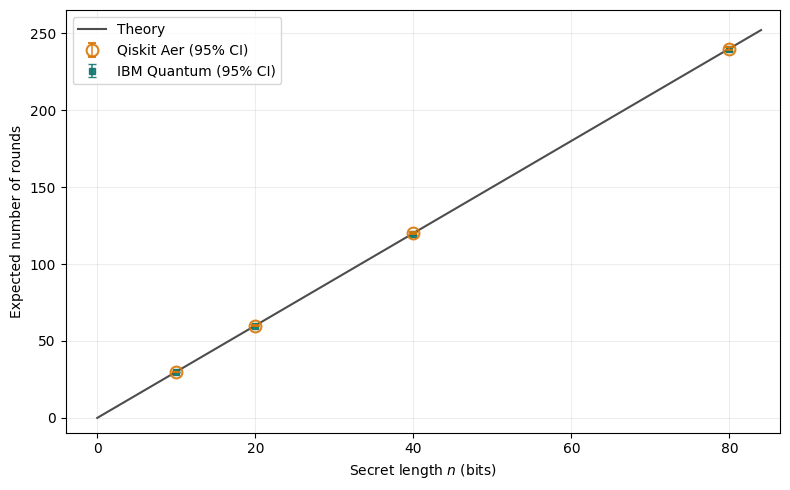

IBM estimated rounds per transmitted secret bit: 2.994530 (95% CI [2.977552, 3.011979])
IBM bit error rate of the reconstructed secret: 4.30% (mean over encoded bits 0 and 1; before security-test acceptance or error correction)


In [18]:
eff_aer = round_statistics(aer_clean_raw)
eff_ibm = round_statistics(qpu["efficiency"])

fig, ax = plt.subplots()
x = np.linspace(0, 1.05 * SECRET_LENGTHS.max(), 350)
ax.plot(x, 3 * x, color=THEORY, label="Theory", zorder=1)
for stats, series in ((eff_aer, "Aer"), (eff_ibm, "IBM")):
    y = expected_attempts(stats, SECRET_LENGTHS)
    plot_estimates(ax, SECRET_LENGTHS, y, attempts_ci(stats, SECRET_LENGTHS), series)
ax.set_xlabel("Secret length $n$ (bits)")
ax.set_ylabel("Expected number of rounds")
ax.set_xlim(-4, SECRET_LENGTHS.max() * 1.08)
max_expected = max(3 * SECRET_LENGTHS.max(),
                   *(attempts_ci(stats, SECRET_LENGTHS)[1].max()
                     for stats in (eff_aer, eff_ibm)))
ax.set_ylim(-0.04 * max_expected, 1.10 * max_expected)
ax.legend()
finish_plot(fig, "01_efficiency.pdf")

coefficient = float(expected_attempts(eff_ibm, 1))
coefficient_ci = attempts_ci(eff_ibm, np.array([1]))[:, 0]
print(f"IBM estimated rounds per transmitted secret bit: {coefficient:.6f} "
      f"(95% CI [{coefficient_ci[0]:.6f}, {coefficient_ci[1]:.6f}])")
print(f"IBM bit error rate of the reconstructed secret: {eff_ibm['bit_error']:.2%} "
      "(mean over encoded bits 0 and 1; before security-test acceptance or error correction)")

## 4.2. Intercept-and-Resend Attack

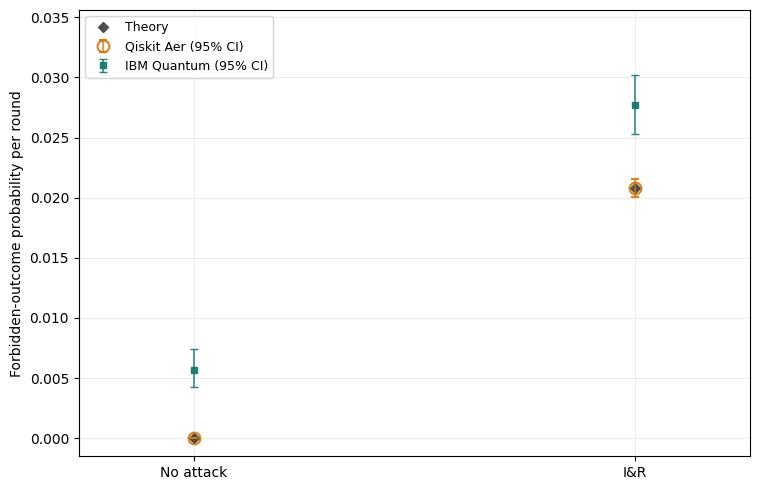

In [514]:
ir_aer = round_statistics(aer_ir_raw)
ir_clean_aer = eff_aer
ir_ibm = round_statistics(qpu["ir"]["IR"])
ir_clean_ibm = round_statistics(qpu["ir"]["clean"])

fig, ax = plt.subplots(figsize=(7.7, 5.0))
ax.plot([0, 1], [0, p_detection("IR")], "D", color=THEORY,
        markersize=5, label="Theory", zorder=1)
for clean, attacked, series in (
    (ir_clean_aer, ir_aer, "Aer"),
    (ir_clean_ibm, ir_ibm, "IBM"),
):
    stats = (clean, attacked)
    y = np.array([single_detection(item) for item in stats])
    ci = np.column_stack([item["detect_ci"] for item in stats])
    plot_estimates(ax, [0, 1], y, ci, series)
ax.set_xticks([0, 1], ["No attack", "I&R"])
ax.set_xlim(-0.26, 1.26)
high = max(p_detection("IR"),
           *(item["detect_ci"][1] for item in
             (ir_clean_aer, ir_aer, ir_clean_ibm, ir_ibm)))
ax.set_ylim(-0.05 * high, 1.18 * high)
ax.set_ylabel("Forbidden-outcome probability per round")
ax.legend(loc="upper left", fontsize=9)
finish_plot(fig, "02_ir_detection.pdf")

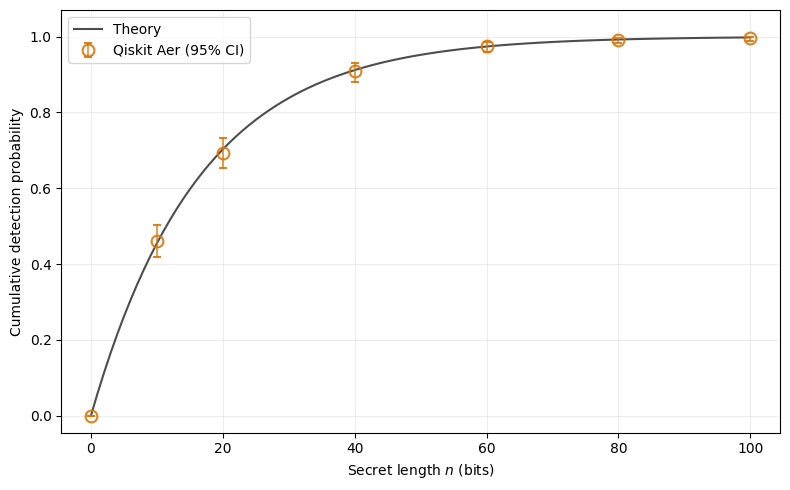

In [515]:
ir_cumulative_aer = cumulative_aer("IR")

fig, ax = plt.subplots()
n = np.arange(CUMULATIVE_LENGTHS[-1] + 1)
ax.plot(n, cumulative_detection(p_detection("IR"), n), color=THEORY, label="Theory")
plot_estimates(ax, CUMULATIVE_LENGTHS, ir_cumulative_aer["probability"],
               ir_cumulative_aer["ci"], "Aer")
ax.set_xlabel("Secret length $n$ (bits)")
ax.set_ylabel("Cumulative detection probability")
pad_probability_axes(ax, xmax=CUMULATIVE_LENGTHS[-1])
ax.legend()
finish_plot(fig, "08_ir_cumulative.pdf")


## 4.3. Entangle-and-Measure Attack

The auxiliary experiment prepares the inputs $|0\rangle$ and $|1\rangle$ equally often and uses the specified ancilla measurement. This characterizes the chosen numerical interaction; it does not restrict the general interaction model to this input pair. Its ideal mutual information equals the accessible-information formula. On hardware, the measured quantity is the information achieved by this measurement, whose optimality for noisy ancillary states is not assumed. It does not represent Bob's total information about the secret.


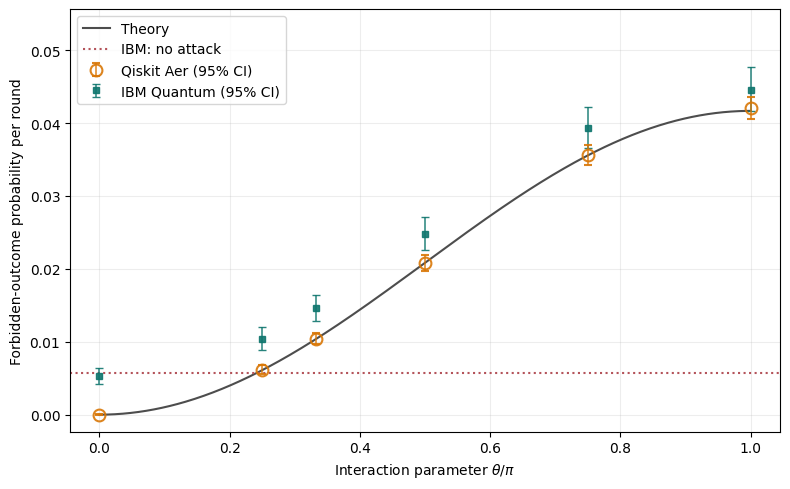

In [516]:
em_aer = {t: round_statistics(raw) for t, raw in aer_em_raw.items()}
em_ibm = {t: round_statistics(raw) for t, raw in qpu["em"]["EM"].items()}
em_clean_ibm = round_statistics(qpu["em"]["clean"])

fig, ax = plt.subplots()
angle = np.linspace(0, np.pi, 500)
ax.plot(angle / np.pi, p_detection("EM", angle), color=THEORY, label="Theory")
for collection, series in ((em_aer, "Aer"), (em_ibm, "IBM")):
    tvals = np.asarray(sorted(collection))
    values = np.array([single_detection(collection[t]) for t in tvals])
    cis = np.column_stack([collection[t]["detect_ci"] for t in tvals])
    plot_estimates(ax, tvals / np.pi, values, cis, series)
ax.axhline(single_detection(em_clean_ibm), color=CONTROL,
           linestyle=":", label="IBM: no attack")
ax.set_xlabel(r"Interaction parameter $\theta/\pi$")
ax.set_ylabel("Forbidden-outcome probability per round")
high = max([p_detection("EM", np.pi), em_clean_ibm["detect_ci"][1]] +
           [stats["detect_ci"][1] for stats in list(em_aer.values()) +
            list(em_ibm.values())])
pad_probability_axes(ax, xmax=1, ymax=max(0.052, high * 1.05))
ax.legend()
finish_plot(fig, "03_em_detection.pdf")

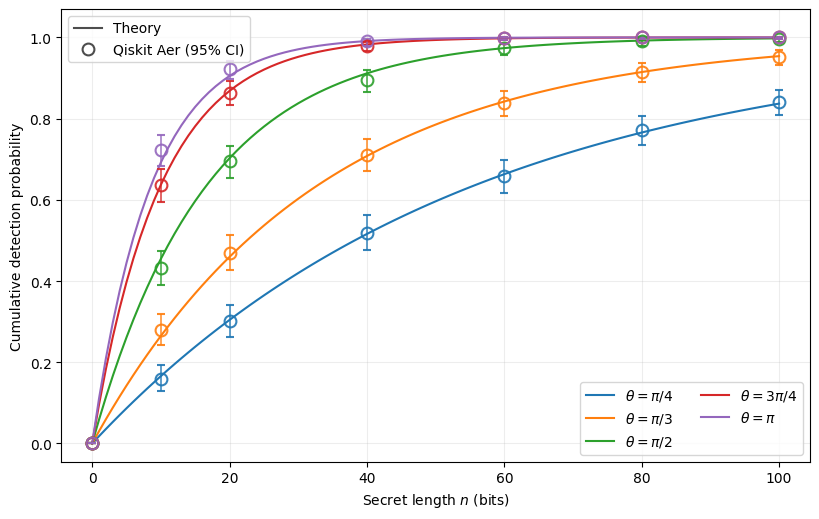

In [517]:
em_cumulative_aer = {float(t): cumulative_aer("EM", float(t))
                     for t in THETA_NONZERO}

fig, ax = plt.subplots(figsize=(8.3, 5.3))
n = np.arange(CUMULATIVE_LENGTHS[-1] + 1)
angle_handles = []
for theta, color, name in zip(THETA_NONZERO, THETA_COLORS, THETA_NAMES):
    line, = ax.plot(n, cumulative_detection(p_detection("EM", theta), n),
                    color=color, label=rf"$\theta={name.strip('$')}$")
    angle_handles.append(line)
    result = em_cumulative_aer[float(theta)]
    plot_estimates(ax, CUMULATIVE_LENGTHS, result["probability"], result["ci"],
                   "Aer", color=color, label="_nolegend_")
source_handles = [Line2D([], [], color=THEORY, label="Theory"),
                  Line2D([], [], color=THEORY, marker="o", linestyle="none",
                         markersize=8.5, markerfacecolor="none", markeredgewidth=1.5,
                         label="Qiskit Aer (95% CI)")]
source_legend = ax.legend(handles=source_handles, loc="upper left")
ax.add_artist(source_legend)
ax.legend(handles=angle_handles, loc="lower right", ncol=2)
ax.set_xlabel("Secret length $n$ (bits)")
ax.set_ylabel("Cumulative detection probability")
pad_probability_axes(ax, xmax=CUMULATIVE_LENGTHS[-1])
finish_plot(fig, "09_em_cumulative.pdf")


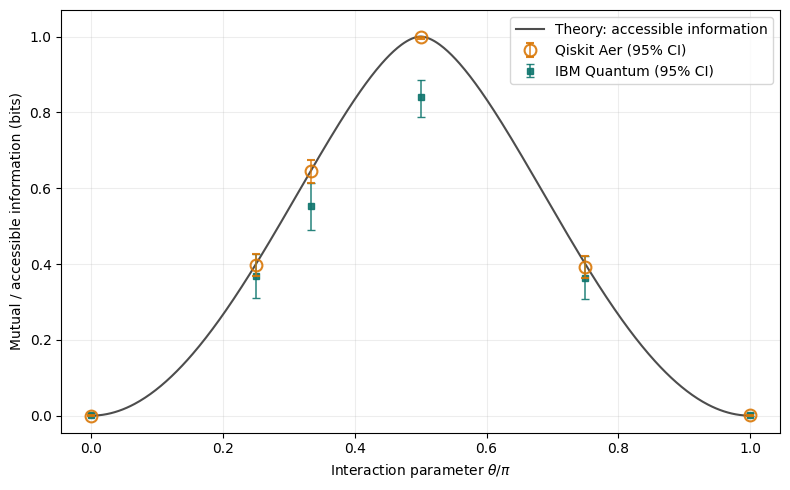

In [518]:
info_aer = {t: information_stats(counts) for t, counts in aer_information_raw.items()}
info_ibm = {t: information_stats(counts) for t, counts in qpu["information"].items()}

fig, ax = plt.subplots()
angle = np.linspace(0, np.pi, 500)
ax.plot(angle / np.pi, information_theory(angle), color=THEORY,
        label="Theory: accessible information")
for collection, series in ((info_aer, "Aer"), (info_ibm, "IBM")):
    tvals = np.asarray(sorted(collection))
    values = np.array([collection[t]["information"] for t in tvals])
    cis = np.column_stack([collection[t]["ci"] for t in tvals])
    plot_estimates(ax, tvals / np.pi, values, cis, series)
ax.set_xlabel(r"Interaction parameter $\theta/\pi$")
ax.set_ylabel("Mutual / accessible information (bits)")
pad_probability_axes(ax, xmax=1)
ax.legend()
finish_plot(fig, "04_em_information.pdf")

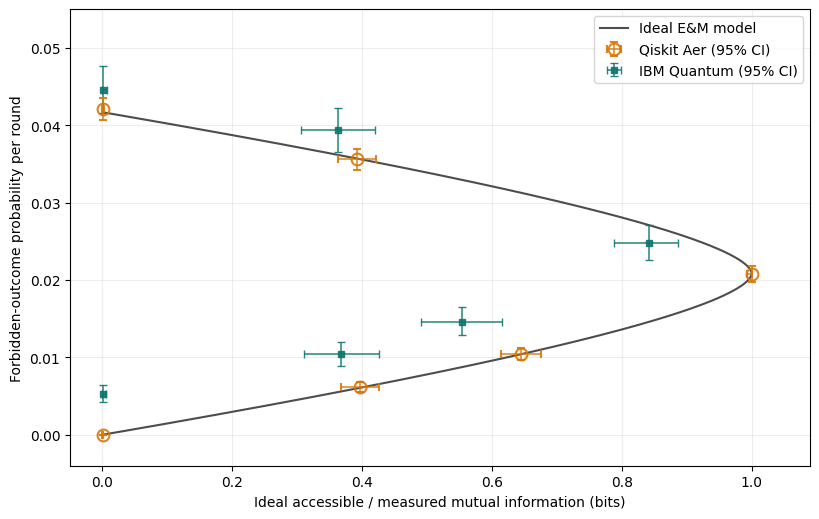

In [519]:
fig, ax = plt.subplots(figsize=(8.3, 5.3))
angle = np.linspace(0, np.pi, 500)
ax.plot(information_theory(angle), p_detection("EM", angle),
        color=THEORY, label="Ideal E&M model")
for info, detection, series in (
    (info_aer, em_aer, "Aer"),
    (info_ibm, em_ibm, "IBM"),
):
    common = sorted(set(info) & set(detection))
    xs = np.array([info[t]["information"] for t in common])
    ys = np.array([single_detection(detection[t]) for t in common])
    xcis = np.column_stack([info[t]["ci"] for t in common])
    ycis = np.column_stack([detection[t]["detect_ci"] for t in common])
    plot_estimates(ax, xs, ys, ycis, series, x_ci=xcis)
ax.set_xlabel("Ideal accessible / measured mutual information (bits)")
ax.set_ylabel("Forbidden-outcome probability per round")
ax.set_xlim(-0.05, 1.09)
high = max(stats["detect_ci"][1] for stats in list(em_aer.values()) + list(em_ibm.values()))
ax.set_ylim(-0.004, max(0.055, 1.10 * high))
ax.legend()
finish_plot(fig, "05_em_information_disturbance.pdf")

## 4.4. Statistical Attack Detection

Only test rounds enter the pooled forbidden-outcome count. A fresh random, disjoint calibration/holdout split is made on every run. The calibration upper bounds use total failure probability `CALIBRATION_DELTA`; the larger of the two bit-conditioned bounds defines the null threshold. The conditional testing level `alpha` and the total calibration failure probability `CALIBRATION_DELTA` are separate parameters.

The detection and false-alarm probabilities are calculated using a binomial model with the forbidden-outcome frequencies measured under attack and in the clean holdout data, respectively. They are not estimated from repeated complete protocol runs on IBM hardware. These projections assume that encoded bits 0 and 1 occur independently with equal probability and that test configurations are sampled according to the protocol. The false-alarm guarantee is conditional on independent, stationary trials and the protocol's configuration sampling; it is not a guarantee for every fixed configuration sequence or against arbitrary attacks.

Conditional on calibration covering both clean bit-conditioned probabilities, the clean false-alarm probability is at most `alpha`. Including calibration failure gives the bound `alpha + (1-alpha)*CALIBRATION_DELTA`, under the stated model assumptions. With `CALIBRATION_DELTA = 0.05`, these conservative unconditional bounds are 0.0595 and 0.0975 for the plotted levels 0.01 and 0.05. The plotted holdout projections are not these worst-case bounds. The decision rule is for one terminal test, not repeated outcome-dependent monitoring.


In [520]:
def split_template_counts(data, fraction=0.5):
    """Random disjoint calibration/holdout split without expanding shot lists."""
    rng = np.random.default_rng()
    left, right = {}, {}
    for key, counts in data.items():
        strings = sorted(counts)
        vector = np.array([counts[s] for s in strings], dtype=int)
        size = int(vector.sum())
        n_cal = int(size * fraction)
        if n_cal < 2 or size - n_cal < 2:
            raise ValueError("At least four shots per template are required")
        selected = rng.multivariate_hypergeometric(vector, n_cal)
        left[key] = dict(zip(strings, selected.tolist()))
        right[key] = dict(zip(strings, (vector - selected).tolist()))
    return left, right


def calibrated_null(control_data):
    cal, holdout = split_template_counts(control_data)
    cal_totals = aggregate_round_counts(cal)
    eval_totals = aggregate_round_counts(holdout)
    upper = [upper_probability_bound(cal_totals[b]["forbidden"],
                                     cal_totals[b]["test_shots"], CALIBRATION_DELTA / 2)
             for b in (0, 1)]
    p0 = np.mean([eval_totals[b]["forbidden"] / eval_totals[b]["test_shots"] for b in (0, 1)])
    return float(max(upper)), float(p0)


def critical_threshold(m_T, alpha, null_upper):
    """Smallest k with Pr[Bin(m_T, null_upper) >= k] <= alpha."""
    if not isinstance(m_T, (int, np.integer)) or m_T < 0:
        raise ValueError("Test count must be a nonnegative integer")
    if not 0 < alpha < 1 or not 0 <= null_upper <= 1:
        raise ValueError("Expected 0 < alpha < 1 and 0 <= null_upper <= 1")
    lower, upper = 1, int(m_T) + 1
    while lower < upper:
        middle = (lower + upper) // 2
        if binom.sf(middle - 1, m_T, null_upper) <= alpha:
            upper = middle
        else:
            lower = middle + 1
    return lower


def threshold_study(clean_data, attack_data):
    u, p0 = calibrated_null(clean_data)
    attack_rates = {}
    for name, data in attack_data.items():
        totals = aggregate_round_counts(data)
        attack_rates[name] = float(np.mean([totals[b]["forbidden"] / totals[b]["test_shots"]
                                             for b in (0, 1)]))
    result = {}
    for alpha in ALPHAS:
        critical = np.array([critical_threshold(int(m_T), alpha, u)
                             for m_T in TEST_COUNTS])
        result[alpha] = {
            "critical": critical,
            "fp": binom.sf(critical - 1, TEST_COUNTS, p0),
            "fp_bound": binom.sf(critical - 1, TEST_COUNTS, u),
            "tp": {name: binom.sf(critical - 1, TEST_COUNTS, p)
                   for name, p in attack_rates.items()},
        }
        if np.any(result[alpha]["fp_bound"] > alpha + 1e-10):
            raise AssertionError("Null-tail calibration error")
    return result


threshold_ir = threshold_study(qpu["ir"]["clean"], {"I&R": qpu["ir"]["IR"]})
threshold_em = threshold_study(qpu["em"]["clean"], qpu["em"]["EM"])

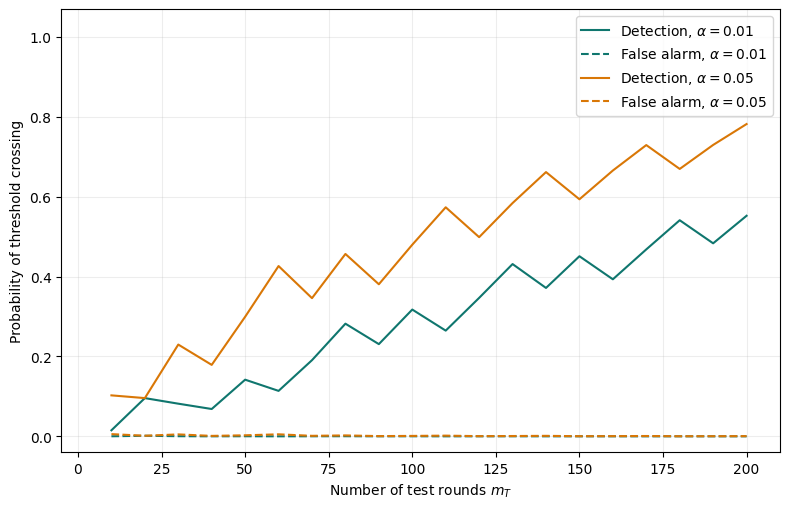

In [4]:
fig, ax = plt.subplots(figsize=(8.0, 5.2))
for alpha, color in zip(ALPHAS, (IBM, AER)):
    res = threshold_ir[alpha]
    ax.plot(TEST_COUNTS, res["tp"]["I&R"], color=color,
            label=rf"Detection, $\alpha={alpha:g}$")
    ax.plot(TEST_COUNTS, res["fp"], "--", color=color,
            label=rf"False alarm, $\alpha={alpha:g}$")
ax.set_xlabel("Number of test rounds $m_T$")
ax.set_ylabel("Probability of threshold crossing")
ax.set_xlim(-5, 210)
ax.set_ylim(-0.04, 1.07)
ax.legend()
finish_plot(fig, "06_ir_threshold.pdf")

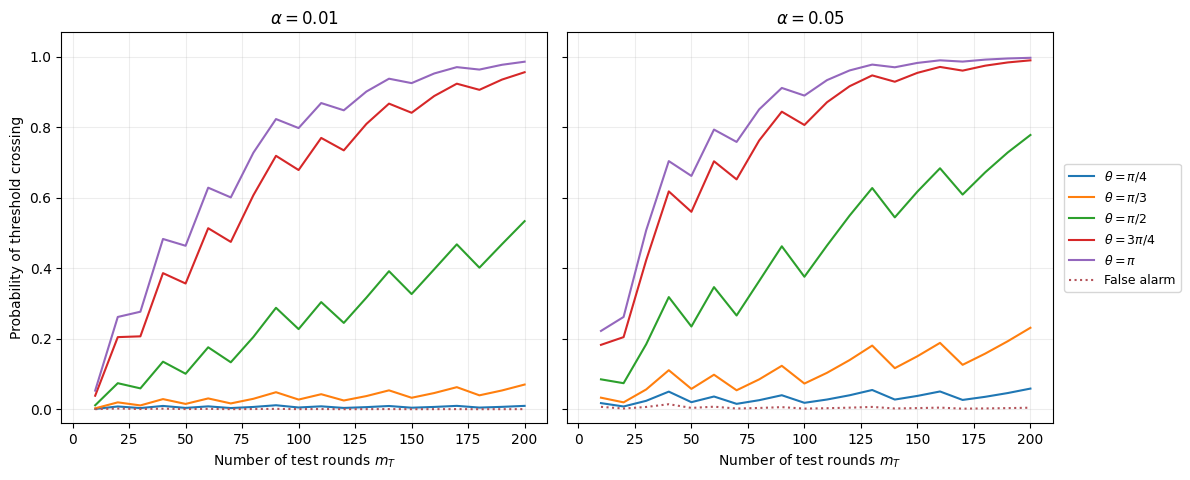

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.9), sharey=True)
for ax, alpha in zip(axes, ALPHAS):
    results = threshold_em[alpha]
    for color, theta, name in zip(THETA_COLORS, THETA_NONZERO, THETA_NAMES):
        ax.plot(TEST_COUNTS, results["tp"][float(theta)],
                color=color, label=rf"$\theta={name.strip('$')}$")
    ax.plot(TEST_COUNTS, results["fp"], ":", color=CONTROL,
            label="False alarm")
    ax.set_xlabel("Number of test rounds $m_T$")
    ax.set_title(rf"$\alpha={alpha:g}$")
    ax.set_xlim(-5, 210)
    ax.set_ylim(-0.04, 1.07)
axes[0].set_ylabel("Probability of threshold crossing")
axes[1].legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=9)
finish_plot(fig, "07_em_threshold.pdf")